In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline 
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
from sklearn.model_selection import KFold , cross_validate , GridSearchCV
from sklearn.base import clone
import joblib 

In [2]:
df = pd.read_csv(
    "../data/ai_jobs_salaries_with_exposure.csv"
)

ai_df = pd.read_excel(
    "../data/Final_Scores_ISCO08_Gmyrek_et_al_2025.xlsx"
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (71913, 22)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,...,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint,ISCO_08,Title,mean_score_2025,SD_2025,potential25
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,...,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...,1330.0,Information and Communications Technology Serv...,0.44,0.07,Exposed: Gradient 2
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,...,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...,1330.0,Information and Communications Technology Serv...,0.44,0.07,Exposed: Gradient 2
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,...,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians",2120.0,"Mathematicians, Actuaries and Statisticians",0.56,0.09,Exposed: Gradient 3
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,...,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians",2120.0,"Mathematicians, Actuaries and Statisticians",0.56,0.09,Exposed: Gradient 3
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,...,Full-time,Remote,False,Other / Unclassified,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
target = "mean_score_2025"

print("Missing target values:", df[target].isna().sum())

print("\nTarget statistics:")
print(df[target].describe())

print("\nUnique target values:")
print(df[target].nunique())

Missing target values: 43392

Target statistics:
count    28521.000000
mean         0.512630
std          0.061464
min          0.420000
25%          0.420000
50%          0.550000
75%          0.560000
max          0.560000
Name: mean_score_2025, dtype: float64

Unique target values:
4


In [4]:
model_df = df.dropna(subset=[target]).copy()

print("Rows available for modeling:", model_df.shape[0])
print("Number of unique job titles:", model_df["job_title"].nunique())
print("Number of unique ISCO codes:", model_df["ISCO_08"].nunique())

Rows available for modeling: 28521
Number of unique job titles: 82
Number of unique ISCO codes: 4


In [5]:
ai_occupation = (
    ai_df[
        [
            "ISCO_08",
            "Title",
            "mean_score_2025",
            "SD_2025",
            "potential25"
        ]
    ]
    .drop_duplicates(subset=["ISCO_08"])
    .copy()
)

print("Unique occupations:", len(ai_occupation))

print("\nUnique exposure scores:")
print(ai_occupation["mean_score_2025"].nunique())

print("\nExposure score statistics:")
print(ai_occupation["mean_score_2025"].describe())

print("\nExposure categories:")
print(ai_occupation["potential25"].value_counts(dropna=False))

Unique occupations: 427

Unique exposure scores:
58

Exposure score statistics:
count    427.000000
mean       0.296511
std        0.144897
min        0.090000
25%        0.180000
50%        0.270000
75%        0.390000
max        0.700000
Name: mean_score_2025, dtype: float64

Exposure categories:
potential25
Not Exposed            231
Minimal Exposure        84
Exposed: Gradient 2     44
Exposed: Gradient 3     38
Exposed: Gradient 1     17
Exposed: Gradient 4     13
Name: count, dtype: int64


In [6]:
print(ai_df.columns.tolist())

['label4d', 'label1d', 'ISCO_08', 'Title', 'taskID', 'Task_ISCO', 'score_2023', 'Weaviate Status', 'predicted_score_2025_gpt4o', 'prediction_justification_gpt4o', 'weaviate_status_gemini', 'predicted_score_2025_gemini', 'prediction_justification_gemini', 'score_2025', 'source', 'mean_score_2023', 'mean_score_2025', 'SD_2023', 'SD_2025', 'potential25', 'potential23']


In [7]:
ai_df[
    [
        "ISCO_08",
        "Title",
        "Task_ISCO",
        "mean_score_2025",
        "potential25"
    ]
].head(10)

,ISCO_08,Title,Task_ISCO,mean_score_2025,potential25
0,1111,Legislators,Presiding over or participating in the proceed...,0.31,Not Exposed
1,1111,Legislators,"Determining, formulating and directing policie...",0.31,Not Exposed
2,1111,Legislators,"Making, ratifying, amending or repealing laws,...",0.31,Not Exposed
3,1111,Legislators,Serving on government administrative boards or...,0.31,Not Exposed
4,1111,Legislators,Investigating matters of concern to the public...,0.31,Not Exposed
5,1111,Legislators,Attending community functions and meetings to ...,0.31,Not Exposed
6,1111,Legislators,Negotiating with other legislators and represe...,0.31,Not Exposed
7,1111,Legislators,"As members of the government, directing senior...",0.31,Not Exposed
8,1112,Senior Government Officials,"Advising national, state, regional or local go...",0.38,Minimal Exposure
9,1112,Senior Government Officials,Advising on the preparation of government budg...,0.38,Minimal Exposure


In [8]:
occupation_df = (
    ai_df.groupby(
        ["ISCO_08", "Title"],
        as_index=False
    )
    .agg(
        tasks=("Task_ISCO", lambda x: " ".join(x.dropna().astype(str))),
        mean_score_2025=("mean_score_2025", "first"),
        potential25=("potential25", "first")
    )
)

print("Dataset shape:", occupation_df.shape)
print("Unique occupations:", occupation_df["ISCO_08"].nunique())

occupation_df.head()

Dataset shape: (427, 5)
Unique occupations: 427


,ISCO_08,Title,tasks,mean_score_2025,potential25
0,1111,Legislators,Presiding over or participating in the proceed...,0.31,Not Exposed
1,1112,Senior Government Officials,"Advising national, state, regional or local go...",0.38,Minimal Exposure
2,1113,Traditional Chiefs and Heads of Villages,Allocating the use of communal land and other ...,0.23,Not Exposed
3,1114,Senior Officials of Special-interest Organizat...,"Determining and formulating the policies, rule...",0.37,Minimal Exposure
4,1120,Managing Directors and Chief Executives,"Planning, directing and coordinating the gener...",0.38,Minimal Exposure


In [9]:
print("Missing task descriptions:", occupation_df["tasks"].isna().sum())
print("Missing exposure scores:", occupation_df["mean_score_2025"].isna().sum())
print("Duplicate ISCO codes:", occupation_df["ISCO_08"].duplicated().sum())

print("\nExposure score range:")
print(occupation_df["mean_score_2025"].describe())

Missing task descriptions: 0
Missing exposure scores: 0
Duplicate ISCO codes: 0

Exposure score range:
count    427.000000
mean       0.296511
std        0.144897
min        0.090000
25%        0.180000
50%        0.270000
75%        0.390000
max        0.700000
Name: mean_score_2025, dtype: float64


In [10]:
occupation_df["text"] = (
    occupation_df["Title"].fillna("")
    + " "
    + occupation_df["tasks"].fillna("")
)
X = occupation_df["text"]
y = occupation_df["mean_score_2025"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (427,)
y shape: (427,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 341
Testing samples: 86


In [12]:
model = Pipeline([
    ("tfidf" , TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        min_df=2,
        ngram_range=(1,2),
        max_features=5000
    )),
    ("ridge" , Ridge(alpha=1.0))
])

In [13]:
model.fit(X_train , y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test , y_pred)
mae = mean_absolute_error(y_test , y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.0484
RMSE: 0.0659
R²:   0.7718


In [14]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train.to_frame() , y_train)

baseline_pred = baseline.predict(X_test.to_frame())

baseline_r2 = r2_score(y_test , baseline_pred)
baseline_mae = mean_absolute_error(y_test , baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test,baseline_pred))

print(f"baseline MAE:  {baseline_mae:.4f}")
print(f"baseline RMSE: {baseline_rmse:.4f}")
print(f"baseline R²:   {baseline_r2:.4f}")

baseline MAE:  0.1150
baseline RMSE: 0.1381
baseline R²:   -0.0034


In [15]:
cv  = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    model,
    X,
    y,
    cv = cv,
    scoring= {
        "mae" : "neg_mean_absolute_error",
        "rmse" : "neg_root_mean_squared_error",
        "r2" : "r2"
    },
    n_jobs=-1
)

mae_scores = -cv_results["test_mae"]
rmse_scores = -cv_results["test_rmse"]
r2_scores = cv_results["test_r2"]

print(f"CV MAE:  {mae_scores.mean():.4f} ± {mae_scores.std():.4f}")
print(f"CV RMSE: {rmse_scores.mean():.4f} ± {rmse_scores.std():.4f}")
print(f"CV R²:   {r2_scores.mean():.4f} ± {r2_scores.std():.4f}")

CV MAE:  0.0560 ± 0.0047
CV RMSE: 0.0744 ± 0.0054
CV R²:   0.7330 ± 0.0322


In [16]:
param_grid = {
    "ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best alpha:", grid_search.best_params_["ridge__alpha"])
print("Best CV MAE:", -grid_search.best_score_)

Best alpha: 0.01
Best CV MAE: 0.04932879234233209


In [17]:
param_grid = {
    "ridge__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best alpha:", grid_search.best_params_["ridge__alpha"])
print("Best CV MAE:", -grid_search.best_score_)

Best alpha: 0.0001
Best CV MAE: 0.04925646523497828


In [18]:
final_model = clone(model).set_params(
    ridge__alpha=0.01
)

final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, y_pred_final)
final_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_final)
)
final_r2 = r2_score(y_test, y_pred_final)

print(f"Test MAE:  {final_mae:.4f}")
print(f"Test RMSE: {final_rmse:.4f}")
print(f"Test R²:   {final_r2:.4f}")

Test MAE:  0.0372
Test RMSE: 0.0529
Test R²:   0.8530


In [19]:
results_df = occupation_df.loc[
    X_test.index,
    ["ISCO_08", "Title", "mean_score_2025", "potential25"]
].copy()

results_df["predicted_exposure"] = y_pred_final

results_df["absolute_error"] = (
    results_df["mean_score_2025"]
    - results_df["predicted_exposure"]
).abs()

results_df = results_df.sort_values(
    "absolute_error",
    ascending=False
)

results_df.head(10)

,ISCO_08,Title,mean_score_2025,potential25,predicted_exposure,absolute_error
225,4323,Transport Clerks,0.50,Exposed: Gradient 3,0.306183,0.193817
94,2513,Web and Multimedia Developers,0.60,Exposed: Gradient 4,0.438804,0.161196
165,3312,Credit and Loans Officers,0.60,Exposed: Gradient 4,0.462829,0.137171
419,9611,Garbage and Recycling Collectors,0.09,Not Exposed,0.222892,0.132892
351,7542,Shotfirers and Blasters,0.12,Not Exposed,0.230783,0.110783
208,4211,Bank Tellers and Related Clerks,0.58,Exposed: Gradient 3,0.483365,0.096635
141,3143,Forestry Technicians,0.21,Not Exposed,0.301296,0.091296
172,3324,Trade Brokers,0.44,Exposed: Gradient 2,0.353297,0.086703
358,8114,"Cement, Stone and Other Mineral Products Machi...",0.23,Not Exposed,0.147191,0.082809
281,6210,Forestry and Related Workers,0.12,Not Exposed,0.201965,0.081965


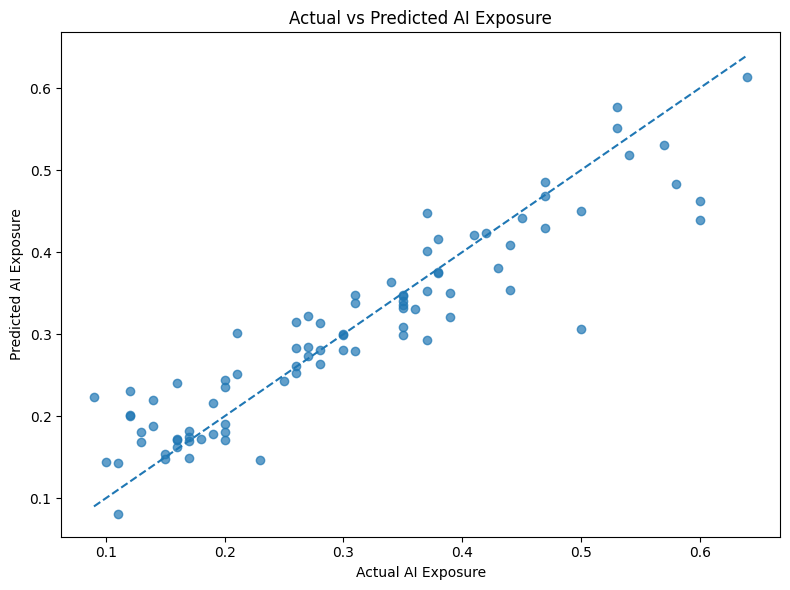

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual AI Exposure")
plt.ylabel("Predicted AI Exposure")
plt.title("Actual vs Predicted AI Exposure")

plt.tight_layout()
plt.show()

## Model 1: Predicting Occupational Exposure to Generative AI

### Objective

The objective of this model is to predict the level of occupational exposure to Generative AI (GenAI) using job titles and task descriptions. The target variable, `mean_score_2025`, represents the occupation-level mean exposure score from the external AI exposure dataset.

AI exposure should not be interpreted as a direct measure of job loss or as evidence that AI causes salaries to decrease.

### Dataset Preparation

The original AI exposure dataset contains task-level records, with multiple tasks associated with each occupation. To avoid treating individual tasks as independent occupations, the data was aggregated to the occupation level using `ISCO_08` and `Title`.

- **Number of occupations:** 427
- **Input features:** Job titles and aggregated task descriptions
- **Target variable:** `mean_score_2025`
- **Unique target values:** 58

### Methodology

A text-based regression pipeline was developed using:

1. **TF-IDF Vectorization:** Converts occupation titles and task descriptions into numerical text features.
2. **Ridge Regression:** Predicts the continuous AI exposure score while applying L2 regularization to control model complexity.
3. **Train-Test Split:** 80% of the occupations were used for training and 20% were reserved for final testing, using `random_state=42`.
4. **Cross-Validation and Hyperparameter Tuning:** Five-fold cross-validation and `GridSearchCV` were used to compare regularization strengths.

The hyperparameter search identified `alpha=0.0001` as the lowest-MAE candidate among the tested values. However, `alpha=0.01` achieved nearly identical cross-validation performance and was selected for the final evaluation.

### Model Evaluation

The final Ridge model was evaluated on the held-out test set.

| Metric | Test Result |
|---|---:|
| Mean Absolute Error (MAE) | 0.0372 |
| Root Mean Squared Error (RMSE) | 0.0529 |
| R² Score | 0.8530 |

The model achieved a test MAE of 0.0372, indicating that its average absolute prediction error was approximately 0.037 exposure-score units. The R² score of 0.8530 indicates that the model explained approximately 85.3% of the target variance relative to a mean-prediction baseline on this test split.

Five-fold cross-validation for the initial Ridge configuration (`alpha=1.0`) produced a mean MAE of 0.0560 ± 0.0047 and a mean R² of 0.7330 ± 0.0322. These results provide an additional assessment of performance variability across folds.

### Actual vs. Predicted Analysis

The scatter plot compares actual exposure scores with model predictions. Many predictions follow the overall trend of the actual values, although some occupations show substantial prediction errors.

The model tends to predict some high-exposure occupations below their actual scores and some low-exposure occupations above their actual scores. These errors suggest that text features alone may not capture all occupation-specific differences in exposure.

### Limitations

- The dataset contains only 427 unique occupations, which limits the conclusions that can be drawn about generalization to unseen occupations.
- Model performance depends on the quality and coverage of the occupation-level exposure scores and task descriptions.
- A random train-test split may produce optimistic results when occupations have similar titles or task descriptions.
- The model predicts reference exposure scores; it does not estimate the causal effect of AI on employment, job displacement, or salary changes.
- Test performance should be interpreted alongside cross-validation results rather than as a guarantee of performance on new occupations.

### Conclusion

The TF-IDF and Ridge Regression pipeline achieved promising predictive performance on the held-out test set and outperformed the mean-prediction baseline in the initial evaluation. Further validation, error analysis, and evaluation on more diverse occupations would strengthen confidence in the model.

This model provides a starting point for analyzing occupational exposure to Generative AI. The next stage of the project examines the relationship between AI exposure and salary using the combined salary and exposure dataset.

In [23]:
# Create models directory if it doesn't exist
Path("../models").mkdir(parents=True , exist_ok= True)

# Train the selected model on all occupations
deployment_model = clone(model).set_params(
    ridge__alpha=0.01
)

deployment_model.fit(X,y)

# Save the complete pipeline
joblib.dump(
    deployment_model ,
    "../models/ai_exposure_ridge.joblib"
)

['../models/ai_exposure_ridge.joblib']

In [24]:
model_path = Path("../models/ai_exposure_ridge.joblib")
print("file exists :" , model_path.exists())

file exists : True
